# Homework 3 solutions

In [1]:
# you may need to 'pip install ipympl' to get the animation to work
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

## 1. Crank-Nicolson diffusion

(a) We look for a solution $T^n_j = \xi^n e^{-ikx_j}$, which gives

$$\xi = 1 + {\alpha\over 2}\left(e^{ik\Delta x}-2+e^{-ik\Delta x}\right)+ {\alpha\over 2}\xi\left(e^{ik\Delta x}-2+e^{-ik\Delta x}\right)$$

$$\Rightarrow \left(1-\alpha\left[\cos(k\Delta x)-1\right]\right)\xi = 1+\alpha\left[\cos(k\Delta x)-1\right]$$

$$\Rightarrow \xi = \frac{1 - 2\alpha\sin^2\left({k\Delta x\over 2}\right)}{1 + 2\alpha\sin^2\left({k\Delta x\over 2}\right)}.$$

This shows that $|\xi|$ is always less than 1, no matter the value of $\alpha$.

(b) At large $\alpha$, $\xi\rightarrow -1$. This means that the modes alternate sign from timestep to timestep, but their amplitude doesn't change. This means that all modes maintain their amplitude, and in particular short wavelength content is conserved, unlike the fully-implicit method where $\xi\rightarrow 0$ for large $\alpha$ so that the short wavelength modes decay quickly.

(c) To implement this, we can see that this is a half-timestep explicit update on the right hand side and then a half-timestep implicit update. So it is fairly straightforward to modify our previous code:

In [2]:
def calculate_A(alpha,N,banded=False):
    b = (1+2*alpha) * np.ones(N)
    a = -alpha * np.ones(N)
    c = -alpha * np.ones(N)    
    # boundary conditions: the temperatures at the ends are fixed
    # so we need to adjust the matrix to give T_end^(n+1) = T_end^n
    # x=0
    b[0] = 1.0
    a[1] = 0.0
    # x=1
    b[-1] = 1.0
    c[-2] = 0.0
    # construct the matrix
    if banded:
        return np.vstack((a,b,c))
    else:
        return np.diag(b, k=0) + np.diag(a[1:], k=1) + np.diag(c[:-1], k=-1)

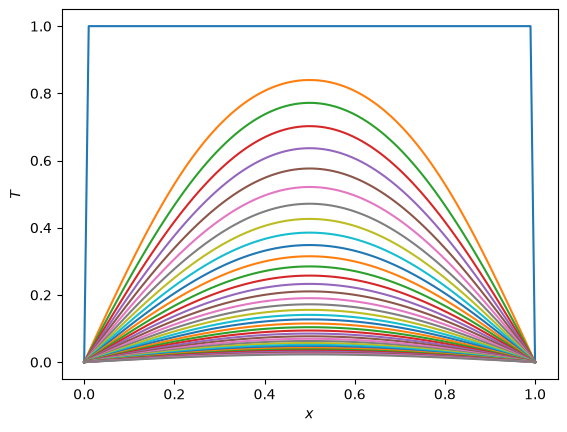

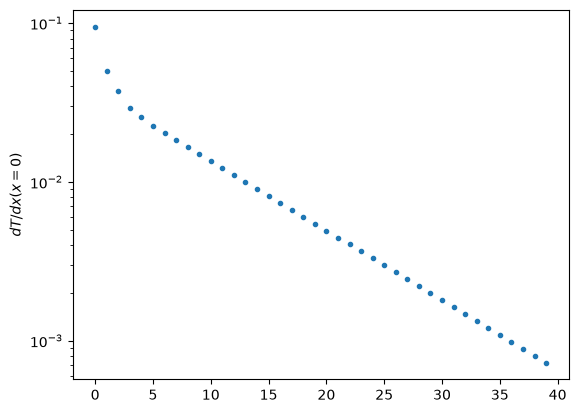

In [3]:
%matplotlib inline

N = 100 # number of grid points
x = np.linspace(0, 1, N)

alpha = 100
nsteps = 40

# Initial profile has T=1 everywhere except T=0 at the boundaries
T = np.ones(N)

# or a centered Gaussian
#sig = 0.04
#T = np.exp(-(x-0.5)**2 /(2*sig**2))

# boundaries
T[0] = 0.0
T[-1] = 0.0

plt.close()
plt.plot(x, T)
plt.xlabel(r'$x$')
plt.ylabel(r'$T$')

# calculate the implicit and explicit updates for half a timestep
Aexp = calculate_A(-alpha/2,N)
Aimp = calculate_A(alpha/2, N)
Aimp1 = calculate_A(alpha, N)

flux = np.zeros(nsteps)

# do a few iterations of fully-implicit before Crank Nicolson
nimp = 3
for i in range(nimp):
    T = np.linalg.solve(Aimp1,T)
    # T[0] =0 so T[1] measures the slope at x=0
    flux[i] = T[1]

# Crank Nicolson
for i in range(nsteps-nimp):
    T = Aexp@T
    T = np.linalg.solve(Aimp,T)

    flux[i+nimp] = T[1]
    
    plt.plot(x, T)

plt.show()

plt.figure()
plt.plot(flux,'.')
plt.yscale('log')
plt.ylabel(r'$dT/dx (x=0)$')
plt.show()

Running this without the fully-implicit steps at the beginning shows short wavelength oscillations near the boundaries. This is a consequence of the behavior found in part (a). Adding just a few implicit steps at the beginning is enough to damp those out.

Notice how the decay is exponential in the later stages, which is what we expect once the higher order modes have decayed and only the last mode (cosine) has significant amplitude.

(d) Now check the scaling with timestep:

[1.16009651e-04 1.38207435e-05 1.32136394e-06 1.49624091e-07
 1.34221889e-08 1.37314385e-09]


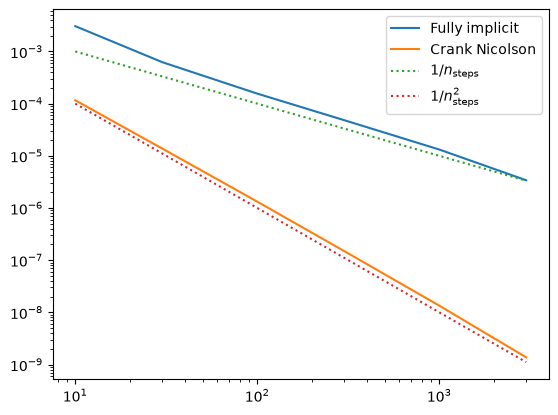

In [4]:
plt.figure()
# Now do this for different numbers of steps
nvec = (10,30,100,300,1000,3000,10000)
fvec = np.zeros_like(nvec,dtype=np.float64)
for j, nsteps in enumerate(nvec):
    alpha = 4000.0 / nsteps
    T = np.ones(N)
    T[0] = 0
    T[-1] = 0

    Aexp = calculate_A(-alpha/2,N)
    Aimp = calculate_A(alpha/2, N)
    Aimp1 = calculate_A(alpha, N)
    
    # do a few iterations of fully-implicit before Crank-Nicolson
    nimp = 3
    for i in range(nimp):
        T = np.linalg.solve(Aimp1,T)

    # Crank Nicolson
    for i in range(nsteps-nimp):
        T = Aexp@T
        T = np.linalg.solve(Aimp,T)

    fvec[j] = T[1]

# same but for fully-implicit
fvec2 = np.zeros_like(nvec,dtype=np.float64)
for j, nsteps in enumerate(nvec):
    alpha = 4000.0 / nsteps
    T = np.ones(N)
    T[0] = 0
    T[-1] = 0
    Aimp1 = calculate_A(alpha, N)

    for i in range(nsteps-nimp):
        T = np.linalg.solve(Aimp1,T)

    fvec2[j] = T[1]

plt.plot(nvec[:-1], np.abs(fvec2[:-1]-fvec2[-1]), label='Fully implicit')
plt.plot(nvec[:-1], np.abs(fvec[:-1]-fvec[-1]), label='Crank Nicolson')

print(np.abs(fvec[:-1]-fvec[-1]))
plt.yscale('log')
plt.xscale('log')
plt.plot(nvec[:-1], 1e-2/np.array(nvec[:-1]),':', label=r'$1/n_\mathrm{steps}$')
plt.plot(nvec[:-1], 1e-2/np.array(nvec[:-1])**2,':', label=r'$1/n_\mathrm{steps}^2$')

plt.legend()


After damping out the short wavelengths with the fully-implicit steps, Crank-Nicolson can be used to get second order accuracy in time.

## 2. Reflection and transmission of an electromagnetic wave

Part (a): Gaussian pulse with $n=1$ everywhere

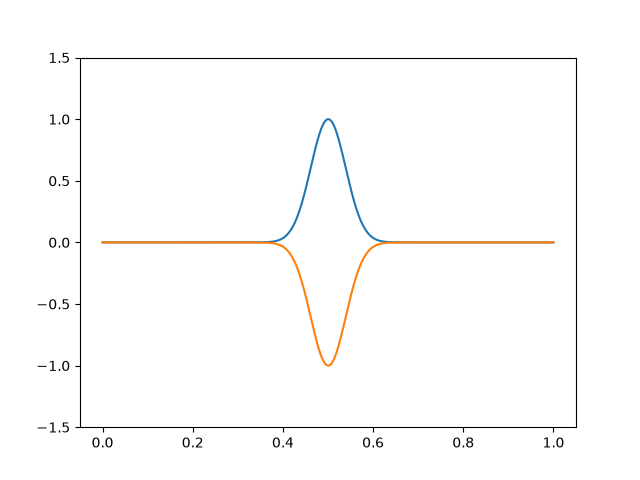

In [7]:
%matplotlib widget

n = 1000

E = np.zeros(n)
x = np.linspace(0,1,n)

i1 = int(0.1*n)
i2 = int(0.2*n)
E = np.exp(-(x-x[n//2])**2/0.003)
# Set the B field to be \pm E: + sign gives right-going, - sign left-going
B = - E.copy()

# we need to store two timesteps for Leapfrog
Ep = E.copy()
Bp = B.copy()

alpha = 0.5

plt.close()
fig, ax = plt.subplots()
dat, = ax.plot(x, E)
dat2, = ax.plot(x, B)
ax.set_ylim(-1.5, 1.5)

def update(k):
    global E, Ep, B, Bp
    
    Enew = Ep - alpha * (np.roll(B,-1) - np.roll(B,1))
    Bnew = Bp - alpha * (np.roll(E,-1) - np.roll(E,1))
    Ep = E
    E = Enew
    Bp = B
    B = Bnew

    dat.set_ydata(E)
    dat2.set_ydata(B)
    print('Step %d' % (k,))
    ax.set_title('Step %d' %(k,))
    return (dat,dat2)

ani = FuncAnimation(fig, update, frames=100, interval=10, repeat=False)
plt.show()

Part (b): change in $n$

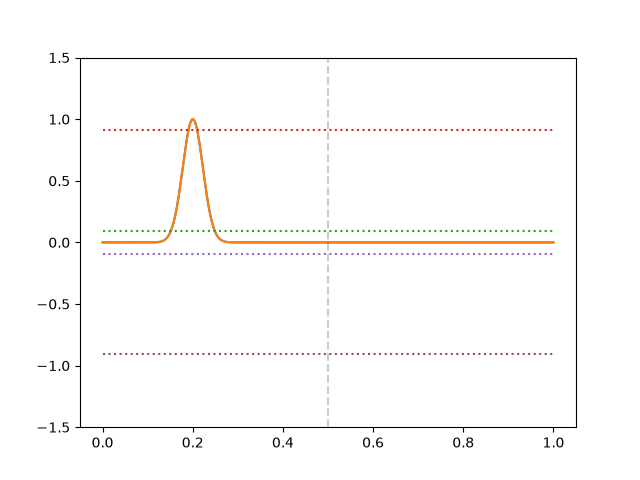

In [6]:
n = 1000

E = np.zeros(n)
x = np.linspace(0,1,n)

# refractive index array
n1 = 1
n2 = 1.2
nr = np.ones_like(x)
nr[:n//2] = n1
nr[n//2:] = n2

i1 = int(0.1*n)
i2 = int(0.2*n)
E = np.exp(-(x-x[n//5])**2/0.001)
# Set the B field to be \pm E: + sign gives right-going, - sign left-going
B = E.copy() * nr

# we need to store two timesteps for Leapfrog
Ep = E.copy()
Bp = B.copy()

alpha = 0.5

plt.close()
fig, ax = plt.subplots()
dat, = ax.plot(x, E)
dat2, = ax.plot(x, B)

ylim = 1.5
ax.set_ylim(-ylim, ylim)

# analytic transmission and reflection coefficients
r = (n2-n1)/(n2+n1)
t = 2*n1/(n1+n2)
ax.plot((x[0],x[-1]),(r,r),':')
ax.plot((x[0],x[-1]),(t,t),':')
ax.plot((x[0],x[-1]),(-r,-r),':')
ax.plot((x[0],x[-1]),(-t,-t),':')

ax.plot((x[n//2],x[n//2]),(-ylim,ylim),'k--',alpha=0.2)

def update(k):
    global E, Ep, B, Bp
    
    Enew = Ep - alpha * (np.roll(B,-1) - np.roll(B,1)) /(nr**2)
    Bnew = Bp - alpha * (np.roll(E,-1) - np.roll(E,1))
    Ep = E
    E = Enew
    Bp = B
    B = Bnew

    dat.set_ydata(E)
    dat2.set_ydata(B)
    print('Step %d' % (k,))
    ax.set_title('Step %d' %(k,))
    return (dat,dat2)

ani = FuncAnimation(fig, update, frames=1000, interval=1, repeat=False)
plt.show()